# Import Library


In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from gensim.models.fasttext import FastText
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

SEED = 42
np.random.seed(SEED)


# Load Dataset

In [7]:
DATA_PATH = "dataset_preprocessed.csv"

if not os.path.exists(DATA_PATH):
    # Alternatif jika notebook dijalankan dari folder pertemuan-07
    candidates = [
        "../dataset/dataset_preprocessed.csv",
        "../dataset_preprocessed.csv"
    ]
    DATA_PATH = next((p for p in candidates if os.path.exists(p)), DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("Lokasi dataset:", DATA_PATH)
print("Ukuran dataset:", df.shape)
print("Kolom:", df.columns.tolist())
display(df.head())


Lokasi dataset: ../dataset_preprocessed.csv
Ukuran dataset: (123253, 2)
Kolom: ['content', 'processed_text']


,content,processed_text
0,Mantap,mantap
1,Bagus dan mudah digunakan,bagus mudah
2,Good,good
3,Sangat membantu orang menengah mantap semoga s...,bantu orang tengah mantap moga sukses gopay
4,Ga ribet .. Sukaaaa,ga ribet sukaaaa


In [ ]:
# Dataset milik praktikum berisi 'content' dan 'processed_text'.
# Gunakan processed_text yang sudah diproses; jika tidak ada, gunakan content.
text_column = "processed_text" if "processed_text" in df.columns else "content"
df = df.dropna(subset=[text_column]).copy()
df[text_column] = df[text_column].astype(str).str.strip()
df = df[df[text_column] != ""]

sentences = [text.split() for text in df[text_column] if text.strip()]
sentences = [tokens for tokens in sentences if tokens]

print("Kolom teks yang digunakan:", text_column)
print("Jumlah teks/kalimat:", len(sentences))
print("Contoh token:", sentences[0][:15] if sentences else "Dataset kosong")
print("Jumlah token keseluruhan:", sum(len(s) for s in sentences))

Kolom teks yang digunakan: processed_text
Jumlah teks/kalimat: 119613
Contoh token: ['mantap']
Jumlah token keseluruhan: 537966


# Melatih Model Word2Vec

In [9]:
model_w2v = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10,
    sg=1,
    seed=SEED
)

print("Model Word2Vec (Skip-gram) berhasil dilatih.")
print("Ukuran vocabulary:", len(model_w2v.wv))


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Model Word2Vec (Skip-gram) berhasil dilatih.
Ukuran vocabulary: 9794


# Menyimpan dan Load Model

In [10]:
MODEL_PATH = "word2vec_model.bin"
model_w2v.save(MODEL_PATH)
print("Model disimpan ke:", os.path.abspath(MODEL_PATH))

# Untuk memuat model yang sudah disimpan:
# model_w2v = Word2Vec.load(MODEL_PATH)


Model disimpan ke: d:\NLP\Modul-2\pertemuan-07\word2vec_model.bin


# Melihat Vektor Kata

In [11]:
sample_word = "bagus"

if sample_word in model_w2v.wv:
    vector = model_w2v.wv[sample_word]
    print(f"Vektor kata '{sample_word}'")
    print("Dimensi:", vector.shape)
    print("10 nilai pertama:", vector[:10])
else:
    print(f"Kata '{sample_word}' tidak ditemukan dalam vocabulary.")
    print("Contoh kata yang tersedia:", list(model_w2v.wv.key_to_index)[:20])

Vektor kata 'bagus'
Dimensi: (100,)
10 nilai pertama: [ 0.21170324  0.26783508  0.38012788  0.26687908 -0.249374    0.23337573
  0.08982868  0.71461815 -0.44675434  0.31699702]


# Mencari Kata Paling Mirip

In [12]:
def find_similar_words(word, model=model_w2v, top_n=10):
    if word not in model.wv:
        print(f"Kata '{word}' tidak ada dalam vocabulary.")
        return []
    return model.wv.most_similar(word, topn=min(top_n, len(model.wv) - 1))

test_words = ["bagus", "buruk", "mudah", "aplikasi", "saldo", "transaksi"]

for word in test_words:
    print(f"\nKata yang mirip dengan '{word}':")
    for similar_word, score in find_similar_words(word, model_w2v, top_n=5):
        print(f"  {similar_word:<20} : {score:.4f}")


Kata yang mirip dengan 'bagus':
  baguss               : 0.8055
  bagu                 : 0.7398
  bagusss              : 0.7308
  operasi              : 0.7301
  bagussss             : 0.7271

Kata yang mirip dengan 'buruk':
  konyol               : 0.7187
  sampah               : 0.7111
  jengkel              : 0.7027
  bagong               : 0.6969
  perihal              : 0.6919

Kata yang mirip dengan 'mudah':
  efektif              : 0.8251
  gopaysemua           : 0.7968
  agam                 : 0.7967
  ringkas              : 0.7913
  mudahh               : 0.7862

Kata yang mirip dengan 'aplikasi':
  apk                  : 0.7914
  aplikasinyasangat    : 0.7371
  apl                  : 0.7241
  amplikasi            : 0.7134
  midah                : 0.7055

Kata yang mirip dengan 'saldo':
  etoll                : 0.7739
  mutasi               : 0.7719
  dibatalin            : 0.7637
  etol                 : 0.7588
  masukmasuk           : 0.7539

Kata yang mirip dengan 'transak

# Similarity antar Kata

In [13]:
def word_similarity(word1, word2, model=model_w2v):
    if word1 not in model.wv or word2 not in model.wv:
        return None
    return float(model.wv.similarity(word1, word2))

pairs = [
    ("bagus", "mantap"),
    ("bagus", "buruk"),
    ("mudah", "praktis"),
    ("saldo", "topup"),
    ("transaksi", "pembayaran")
]

print("Similarity antar kata:")
for w1, w2 in pairs:
    score = word_similarity(w1, w2, model_w2v)
    if score is None:
        print(f"{w1} ↔ {w2}: salah satu kata tidak ada dalam vocabulary")
    else:
        print(f"{w1} ↔ {w2}: {score:.4f}")

Similarity antar kata:
bagus ↔ mantap: 0.6186
bagus ↔ buruk: 0.4156
mudah ↔ praktis: 0.7571
saldo ↔ topup: 0.5625
transaksi ↔ pembayaran: salah satu kata tidak ada dalam vocabulary


# Operasi Vektor Kata

In [15]:
def vector_operation(positive, negative=(), top_n=5, model=model_w2v):
    missing = [w for w in list(positive) + list(negative) if w not in model.wv]
    if missing:
        print("Operasi dilewati; kata tidak ditemukan:", missing)
        return []
    result = model.wv.most_similar(
        positive=list(positive),
        negative=list(negative),
        topn=top_n
    )
    for word, score in result:
        print(f"{word:<20} : {score:.4f}")
    return result

print("Contoh operasi: bagus + mudah - buruk")
vector_operation(positive=["bagus", "mudah"], negative=["buruk"])


Contoh operasi: bagus + mudah - buruk
cpat                 : 0.7033
penggunaanya         : 0.7014
fungsional           : 0.6992
menggunakanya        : 0.6964
sanget               : 0.6920


[('cpat', 0.7032635807991028),
 ('penggunaanya', 0.7014023065567017),
 ('fungsional', 0.6991711854934692),
 ('menggunakanya', 0.6964242458343506),
 ('sanget', 0.6919576525688171)]

# Visualisasi dengan PCA

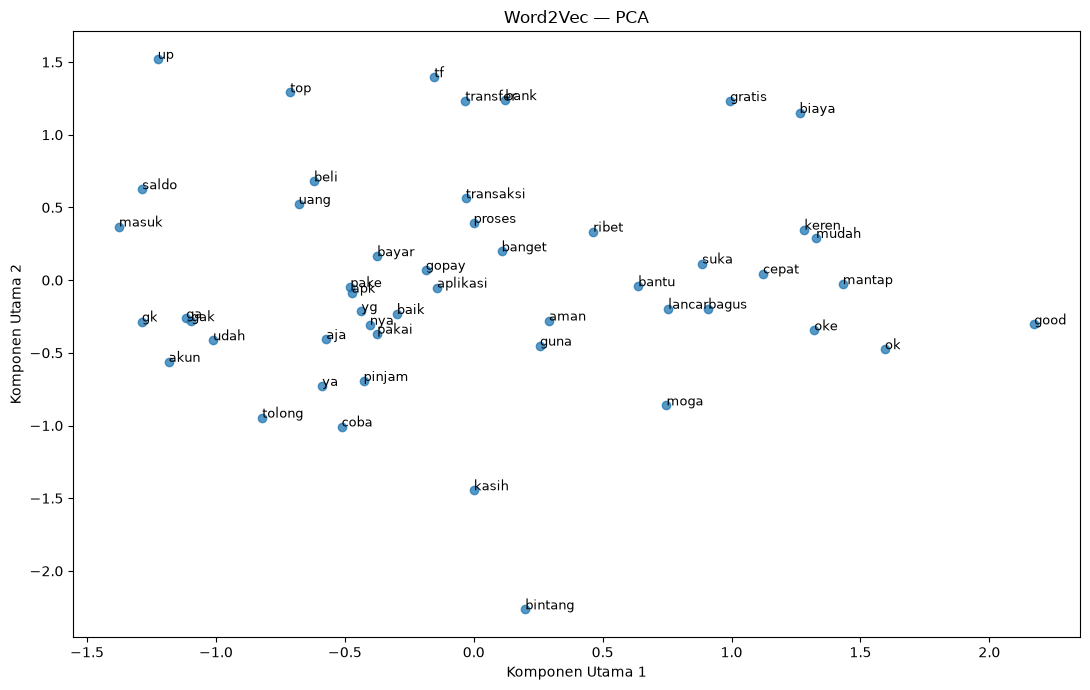

In [16]:
def visualize_embeddings_pca(words, model=model_w2v, title="Word2Vec — PCA"):
    valid_words = list(dict.fromkeys(w for w in words if w in model.wv))
    if len(valid_words) < 2:
        print("Minimal dua kata harus tersedia untuk PCA.")
        return
    vectors = np.array([model.wv[w] for w in valid_words])
    vectors_2d = PCA(n_components=2, random_state=SEED).fit_transform(vectors)

    plt.figure(figsize=(11, 7))
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.75)
    for i, word in enumerate(valid_words):
        plt.annotate(word, (vectors_2d[i, 0], vectors_2d[i, 1]), fontsize=9)
    plt.title(title)
    plt.xlabel("Komponen Utama 1")
    plt.ylabel("Komponen Utama 2")
    plt.tight_layout()
    plt.show()

top_words = list(model_w2v.wv.key_to_index.keys())[:50]
visualize_embeddings_pca(top_words, model_w2v)

# Visualisasi dengan t-SNE

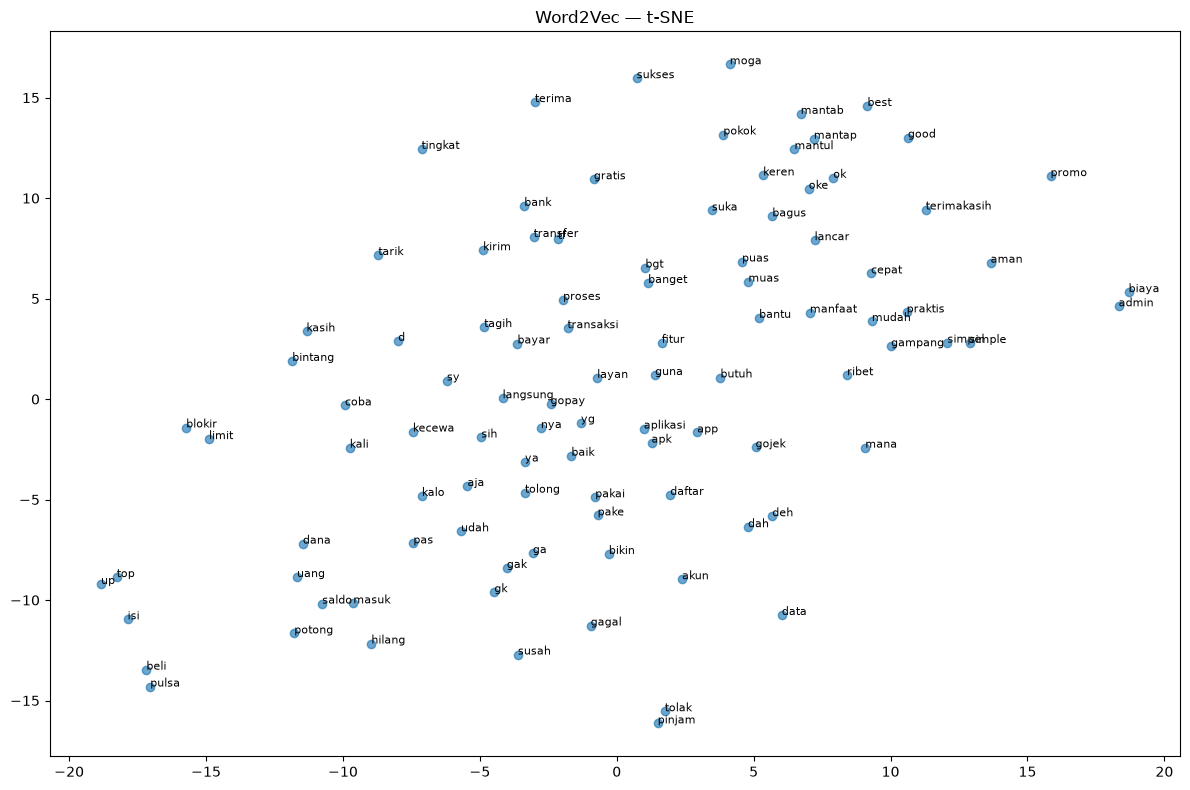

In [19]:
def visualize_embeddings_tsne(words, model=model_w2v, title="Word2Vec — t-SNE"):
    valid_words = list(dict.fromkeys(w for w in words if w in model.wv))
    if len(valid_words) < 3:
        print("Kata yang tersedia terlalu sedikit untuk t-SNE.")
        return
    vectors = np.array([model.wv[w] for w in valid_words])
    # Perplexity harus lebih kecil dari jumlah sampel.
    perplexity = min(15, len(valid_words) - 1)
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=SEED, init="pca", learning_rate="auto")
    vectors_2d = tsne.fit_transform(vectors)

    plt.figure(figsize=(12, 8))
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.65)
    for i, word in enumerate(valid_words):
        plt.annotate(word, (vectors_2d[i, 0], vectors_2d[i, 1]), fontsize=8)
    plt.title(title)
    plt.tight_layout()
    plt.show()

top_words_tsne = list(model_w2v.wv.key_to_index.keys())[:100]
visualize_embeddings_tsne(top_words_tsne, model_w2v)

# Melatih Model Word2Vec — CBOW (sg=0) dan Membandingkan

In [27]:
model_cbow = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10,
    sg=0,
    seed=SEED
)

print("Ukuran vocabulary CBOW:", len(model_cbow.wv))
for word in ["bagus", "buruk", "mudah", "aplikasi"]:
    print(f"\nKata: {word}")
    if word in model_w2v.wv:
        print("Skip-gram:", model_w2v.wv.most_similar(word, topn=5))
    else:
        print("Skip-gram: kata tidak ada dalam vocabulary")
    if word in model_cbow.wv:
        print("CBOW:", model_cbow.wv.most_similar(word, topn=5))
    else:
        print("CBOW: kata tidak ada dalam vocabulary")


Ukuran vocabulary CBOW: 9794

Kata: bagus
Skip-gram: [('baguss', 0.8055213093757629), ('bagu', 0.7398122549057007), ('bagusss', 0.7307709455490112), ('operasi', 0.7300516963005066), ('bagussss', 0.7271008491516113)]
CBOW: [('keren', 0.6993599534034729), ('baguss', 0.6834138035774231), ('rekomendasi', 0.6500231623649597), ('oke', 0.6429914832115173), ('simpel', 0.6151345372200012)]

Kata: buruk
Skip-gram: [('konyol', 0.718686044216156), ('sampah', 0.7110697627067566), ('jengkel', 0.7027108073234558), ('bagong', 0.6968706250190735), ('perihal', 0.691871166229248)]
CBOW: [('kecewa', 0.7748025059700012), ('jelek', 0.7314101457595825), ('keluh', 0.7230395078659058), ('costumer', 0.7118526697158813), ('sampah', 0.6928794384002686)]

Kata: mudah
Skip-gram: [('efektif', 0.8250508308410645), ('gopaysemua', 0.7968282103538513), ('agam', 0.7967051267623901), ('ringkas', 0.7912983298301697), ('mudahh', 0.7862133383750916)]
CBOW: [('praktis', 0.7818213105201721), ('gampang', 0.7461071610450745), ('

# Melatih FastText untuk Kata Berimbuhan/OOV

In [28]:
model_ft = FastText(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10,
    seed=SEED
)

oov_word = "pembayarannya"
vector_oov = model_ft.wv[oov_word]
print(f"FastText menghasilkan vektor untuk '{oov_word}'.")
print("Dimensi vektor:", vector_oov.shape)
print("Apakah kata ada di vocabulary Word2Vec?", oov_word in model_w2v.wv)
print("FastText memanfaatkan subword untuk membentuk vektor kata yang tidak dikenal.")


FastText menghasilkan vektor untuk 'pembayarannya'.
Dimensi vektor: (100,)
Apakah kata ada di vocabulary Word2Vec? False
FastText memanfaatkan subword untuk membentuk vektor kata yang tidak dikenal.


# FastText (Menangani OOV)

In [26]:
model_ft = FastText(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10
)

# FastText dapat menangani kata baru (OOV)
oov_word = "ketidakberhasilannya"  # kata yang mungkin tidak ada di corpus
vector_oov = model_ft.wv[oov_word]
print(f"FastText berhasil menghasilkan vektor untuk '{oov_word}'")
print(f"Dimensi: {vector_oov.shape}")

FastText berhasil menghasilkan vektor untuk 'ketidakberhasilannya'
Dimensi: (100,)


In [ ]:
# Melatih Model Word2Vec — CBOW (sg=0) dan Membandingkan
model_ft = FastText(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10,
    seed=SEED
)

oov_word = "pembayarannya"
vector_oov = model_ft.wv[oov_word]
print(f"FastText menghasilkan vektor untuk '{oov_word}'.")
print("Dimensi vektor:", vector_oov.shape)
print("Apakah kata ada di vocabulary Word2Vec?", oov_word in model_w2v.wv)
print("FastText memanfaatkan subword untuk membentuk vektor kata yang tidak dikenal.")


Ukuran vocabulary CBOW: 9794

Kata: bagus
Skip-gram: [('baguss', 0.8055213093757629), ('bagu', 0.7398122549057007), ('bagusss', 0.7307709455490112), ('operasi', 0.7300516963005066), ('bagussss', 0.7271008491516113)]
CBOW: [('baguss', 0.7212530970573425), ('keren', 0.7110556960105896), ('rekomendasi', 0.6428998708724976), ('oke', 0.6291360259056091), ('komplit', 0.6205753684043884)]

Kata: buruk
Skip-gram: [('konyol', 0.718686044216156), ('sampah', 0.7110697627067566), ('jengkel', 0.7027108073234558), ('bagong', 0.6968706250190735), ('perihal', 0.691871166229248)]
CBOW: [('jelek', 0.7833467721939087), ('kecewa', 0.7827942967414856), ('costumer', 0.736063539981842), ('adu', 0.6943916082382202), ('payah', 0.6845974922180176)]

Kata: mudah
Skip-gram: [('efektif', 0.8250508308410645), ('gopaysemua', 0.7968282103538513), ('agam', 0.7967051267623901), ('ringkas', 0.7912983298301697), ('mudahh', 0.7862133383750916)]
CBOW: [('praktis', 0.7508633136749268), ('gampang', 0.7407439351081848), ('sim

# Perbandingan Word2Vec vs FastText

In [29]:
test_words_oov = ["pembayarannya", "transaksinya", "penggunaannya"]

for word in test_words_oov:
    print(f"\nKata: {word}")
    if word in model_w2v.wv:
        print("Word2Vec:", model_w2v.wv.most_similar(word, topn=5))
    else:
        print("Word2Vec: kata tidak ada dalam vocabulary (OOV)")
    # FastText dapat membentuk vektor berdasarkan subword
    print("FastText:", model_ft.wv.most_similar(word, topn=5))


Kata: pembayarannya
Word2Vec: kata tidak ada dalam vocabulary (OOV)
FastText: [('pembayaranya', 0.9945007562637329), ('pembayaranny', 0.9497924447059631), ('pembelianpembayaran', 0.9485897421836853), ('pembayaranpembelian', 0.9476226568222046), ('prmbayaran', 0.9460636973381042)]

Kata: transaksinya
Word2Vec: kata tidak ada dalam vocabulary (OOV)
FastText: [('transaksi', 0.9406186938285828), ('transaksigak', 0.9292703866958618), ('transaksitransaksi', 0.9281198382377625), ('transaksiiiii', 0.9272639155387878), ('transaksix', 0.9239314198493958)]

Kata: penggunaannya
Word2Vec: kata tidak ada dalam vocabulary (OOV)
FastText: [('penggunaanya', 0.9919734597206116), ('pengunannya', 0.9404968619346619), ('pengoprasiannya', 0.9393357038497925), ('pengunaannya', 0.9378747940063477), ('menggunakanya', 0.933556854724884)]


# Tugas Analisis

In [30]:
# Perbandingan CBOW dan Skip-gram
from gensim.models import Word2Vec

# Mengambil data teks yang sudah diproses
sentences = [
    str(teks).split()
    for teks in df["processed_text"].dropna()
    if str(teks).strip()
]

# Melatih model CBOW
model_cbow = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=0,
    epochs=20
)

# Melatih model Skip-gram
model_skipgram = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=20
)

# Membandingkan kata yang paling mirip
kata_uji = "saldo"

for nama, model in [
    ("CBOW", model_cbow),
    ("Skip-gram", model_skipgram)
]:
    if kata_uji in model.wv:
        print(f"\nKata paling mirip dengan '{kata_uji}' - {nama}:")
        print(model.wv.most_similar(kata_uji, topn=10))
    else:
        print(f"Kata '{kata_uji}' tidak ditemukan pada model {nama}.")


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'



Kata paling mirip dengan 'saldo' - CBOW:
[('mutasi', 0.6679221987724304), ('otomatis', 0.6395691633224487), ('uang', 0.6330139636993408), ('duit', 0.6314419507980347), ('emoney', 0.6238160729408264), ('riwayat', 0.622364342212677), ('refund', 0.606436550617218), ('konfirmasi', 0.599172830581665), ('masuk', 0.590644121170044), ('cek', 0.5857020020484924)]

Kata paling mirip dengan 'saldo' - Skip-gram:
[('ditansfer', 0.7345725297927856), ('hana', 0.7334760427474976), ('jelassaya', 0.7265872359275818), ('ujungujungnya', 0.7202461957931519), ('transaksisaldo', 0.7190554141998291), ('masukmasuk', 0.7186322212219238), ('tolongggg', 0.7148789763450623), ('dibatalin', 0.714465856552124), ('direfund', 0.7128456234931946), ('masuksaldo', 0.7095728516578674)]


In [31]:
# Menghitung similarity 5 pasang kata

pasangan_kata = [
    ("bagus", "baik"),
    ("mudah", "gampang"),
    ("cepat", "lancar"),
    ("saldo", "uang"),
    ("aplikasi", "app")
]

for kata1, kata2 in pasangan_kata:
    print(f"\nPasangan: {kata1} - {kata2}")

    for nama, model in [
        ("CBOW", model_cbow),
        ("Skip-gram", model_skipgram)
    ]:
        if kata1 in model.wv and kata2 in model.wv:
            nilai = model.wv.similarity(kata1, kata2)
            print(f"{nama}: {nilai:.4f}")
        else:
            print(f"{nama}: kata tidak tersedia dalam kosakata model")


Pasangan: bagus - baik
CBOW: 0.3066
Skip-gram: 0.4573

Pasangan: mudah - gampang
CBOW: 0.6825
Skip-gram: 0.7357

Pasangan: cepat - lancar
CBOW: 0.2128
Skip-gram: 0.4034

Pasangan: saldo - uang
CBOW: 0.6330
Skip-gram: 0.6195

Pasangan: aplikasi - app
CBOW: 0.4365
Skip-gram: 0.6151


In [32]:
# Operasi vektor kata

operasi_vektor = [
    {
        "positive": ["bagus", "cepat"],
        "negative": ["buruk"]
    },
    {
        "positive": ["saldo", "transfer"],
        "negative": ["tunai"]
    },
    {
        "positive": ["mudah", "cepat"],
        "negative": ["lambat"]
    }
]

for i, operasi in enumerate(operasi_vektor, start=1):
    print(f"\nOperasi vektor {i}:")

    kata_diperlukan = (
        operasi["positive"] + operasi["negative"]
    )

    if all(kata in model_skipgram.wv for kata in kata_diperlukan):
        hasil = model_skipgram.wv.most_similar(
            positive=operasi["positive"],
            negative=operasi["negative"],
            topn=5
        )
        print(hasil)
    else:
        print("Sebagian kata tidak tersedia dalam kosakata model.")


Operasi vektor 1:
[('pengunaan', 0.69115149974823), ('mantabz', 0.682097852230072), ('fungsional', 0.6612337827682495), ('terbaikkk', 0.6596251726150513), ('menggunakanya', 0.6569461226463318)]

Operasi vektor 2:
[('ditansfer', 0.6519582271575928), ('masuksaldo', 0.6274082660675049), ('terkirimtapi', 0.6222053170204163), ('sea', 0.6152359247207642), ('sinarmas', 0.6014589667320251)]

Operasi vektor 3:
[('efektif', 0.7019771933555603), ('mudahcepat', 0.6821269989013672), ('luarbiasa', 0.660939633846283), ('terbaikkk', 0.656317949295044), ('dann', 0.6550246477127075)]


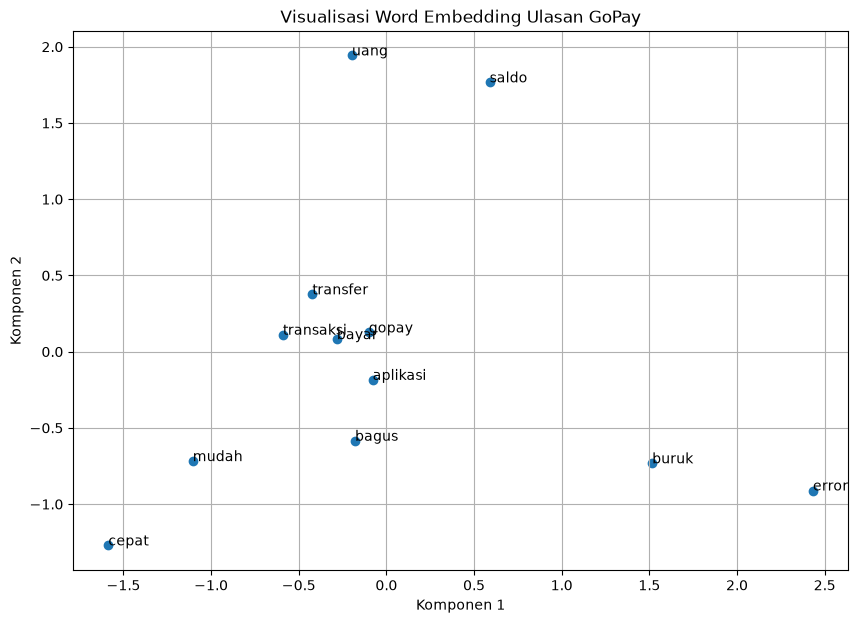

In [33]:
# Visualisasi embedding dan cluster kata

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

kata_visualisasi = [
    kata for kata in [
        "gopay", "saldo", "uang", "transfer",
        "bayar", "aplikasi", "mudah", "cepat",
        "bagus", "buruk", "error", "transaksi"
    ]
    if kata in model_skipgram.wv
]

if len(kata_visualisasi) >= 2:
    vektor = [
        model_skipgram.wv[kata]
        for kata in kata_visualisasi
    ]

    pca = PCA(n_components=2)
    hasil_pca = pca.fit_transform(vektor)

    plt.figure(figsize=(10, 7))
    plt.scatter(hasil_pca[:, 0], hasil_pca[:, 1])

    for i, kata in enumerate(kata_visualisasi):
        plt.annotate(
            kata,
            (hasil_pca[i, 0], hasil_pca[i, 1])
        )

    plt.title("Visualisasi Word Embedding Ulasan GoPay")
    plt.xlabel("Komponen 1")
    plt.ylabel("Komponen 2")
    plt.grid(True)
    plt.show()
else:
    print("Jumlah kata yang tersedia belum cukup untuk visualisasi.")


In [35]:
#  Perbandingan Word2Vec dan FastText

from gensim.models import FastText

# Melatih model FastText
model_fasttext = FastText(
    sentences=sentences,  # bukan kalimat
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1
)

# Kata berimbuhan Bahasa Indonesia
kata_uji = [
    "bayar",
    "membayar",
    "dibayar",
    "pembayaran",
    "transfer",
    "mentransfer"
]

for kata in kata_uji:
    print(f"\nKata: {kata}")

    # Word2Vec
    if kata in model_skipgram.wv:
        print(
            "Word2Vec:",
            model_skipgram.wv.most_similar(kata, topn=3)
        )
    else:
        print("Word2Vec: kata tidak ditemukan")

    # FastText dapat membentuk vektor dari subword
    print(
        "FastText:",
        model_fasttext.wv.most_similar(kata, topn=3)
    )

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'



Kata: bayar
Word2Vec: [('indihome', 0.7301886081695557), ('pulsabayar', 0.719764232635498), ('listrikbayar', 0.7053496837615967)]
FastText: [('kbayar', 0.9861932396888733), ('bayarbayar', 0.9815011620521545), ('mbayar', 0.9813221096992493)]

Kata: membayar
Word2Vec: kata tidak ditemukan
FastText: [('membayarbgmn', 0.9919219017028809), ('membayartpsyh', 0.9908283352851868), ('pembayaranokee', 0.9907666444778442)]

Kata: dibayar
Word2Vec: kata tidak ditemukan
FastText: [('adadibayar', 0.9938269257545471), ('nayar', 0.9911458492279053), ('vayar', 0.9892581105232239)]

Kata: pembayaran
Word2Vec: kata tidak ditemukan
FastText: [('kpembayaran', 0.9988119006156921), ('pembayaranyg', 0.9984195828437805), ('oembayaran', 0.9984044432640076)]

Kata: transfer
Word2Vec: [('tranfer', 0.7587884664535522), ('tf', 0.741279661655426), ('tranfser', 0.7351215481758118)]
FastText: [('transferx', 0.9955217242240906), ('utransfer', 0.9951258897781372), ('uptransfer', 0.9949501156806946)]

Kata: mentransfer
